MLP L=48 run 3/3: 100%|██████████| 3000/3000 [00:07<00:00, 385.54it/s, loss=0.6017]


saved results\test1_gradient_flow.png
saved results\test1_gradient_flow.pdf


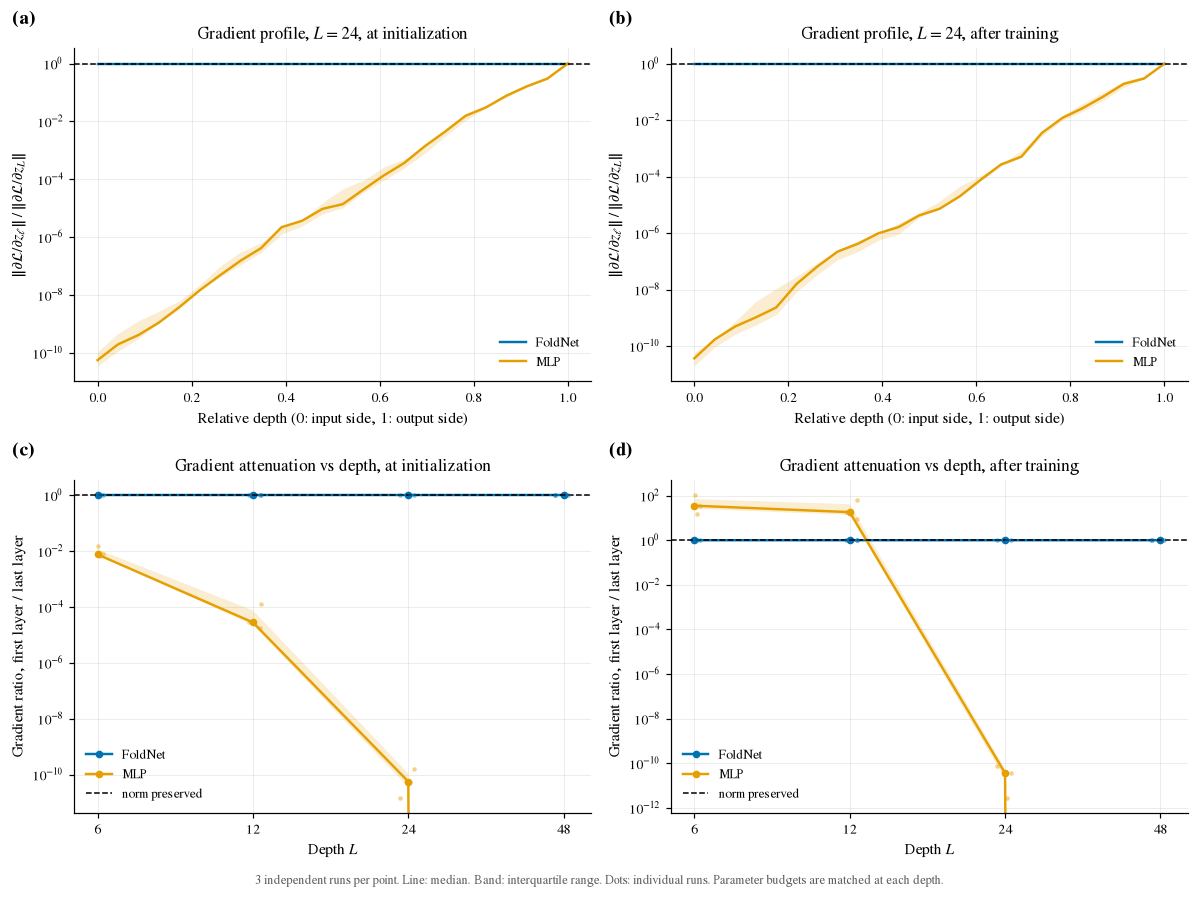

| Depth $L$ | Model | Params | Ratio at init | Ratio after training | Final train MSE |
|---|---|---|---|---|---|
| 6 | FoldNet | 673 | 1.00e+00 [1.00e+00, 1.00e+00] | 1.00e+00 [1.00e+00, 1.00e+00] | 4.54e-02 [4.19e-02, 4.59e-02] |
|  | MLP | 694 | 7.56e-03 [7.20e-03, 1.15e-02] | 3.52e+01 [2.54e+01, 6.95e+01] | 6.46e-02 [6.02e-02, 1.66e-01] |
| 12 | FoldNet | 1249 | 1.00e+00 [1.00e+00, 1.00e+00] | 1.00e+00 [1.00e+00, 1.00e+00] | 3.76e-02 [3.58e-02, 4.08e-02] |
|  | MLP | 1241 | 2.80e-05 [2.28e-05, 7.54e-05] | 1.82e+01 [1.38e+01, 4.12e+01] | 2.01e-01 [1.22e-01, 2.46e-01] |
| 24 | FoldNet | 2401 | 1.00e+00 [1.00e+00, 1.00e+00] | 1.00e+00 [1.00e+00, 1.00e+00] | 2.62e-02 [2.51e-02, 3.33e-02] |
|  | MLP | 2561 | 5.61e-11 [3.56e-11, 1.09e-10] | 3.67e-11 [1.98e-11, 5.75e-11] | 6.03e-01 [6.02e-01, 6.07e-01] |
| 48 | FoldNet | 4705 | 1.00e+00 [1.00e+00, 1.00e+00] | 1.00e+00 [1.00e+00, 1.00e+00] | 3.74e-02 [3.62e-02, 4.50e-02] |
|  | MLP | 4258 | 0.00e+00 [0.00e+00, 0.00e+00] | 0.00e+00 [0.00e+0

In [1]:
"""Test 1: gradient-norm preservation across depth (orthogonal Jacobians, Theorem 3.4(d))."""
import numpy as np
import torch
import matplotlib.pyplot as plt

from foldnet_lib import FoldNet, MLP, n_params, train, DEV
from foldnet_bench import match_budget, make_data, seed_all
import foldnet_viz as V

DEPTHS = [6, 12, 24, 48]
L_SHOW = 24                 # depth used for the per-layer profiles (must be in DEPTHS)
N_RUNS = 3
STEPS = 3000
D, K = 32, 2
NAMES = ["FoldNet", "MLP"]
RESULTS_DIR = "results"
V.COLORS.setdefault("MLP", V.COLORS["MLP (6 layers)"])


def f(x):
    return torch.sin(20 * x) + 0.5 * torch.sin(55 * x)


def grad_norms(model, x, y):
    """Mean per-sample norm of dLoss/dz_l for every hidden activation z_l."""
    model.zero_grad()
    pred, acts = model.forward_with_activations(x)
    loss = ((pred - y) ** 2).mean()
    grads = torch.autograd.grad(loss, acts)
    return np.array([g.flatten(1).norm(dim=1).mean().item() for g in grads])


def one_run(name, depth, r):
    x, y, _, _ = make_data(f, seed=1000 + r)
    x, y = x.to(DEV), y.to(DEV)
    seed_all(r)
    target = n_params(FoldNet(1, 1, D, depth, K))
    if name == "FoldNet":
        m = FoldNet(1, 1, D, depth, K)
    else:
        m = match_budget(lambda w: MLP(1, 1, w, depth), target)
    m = m.to(DEV)
    g_init = grad_norms(m, x, y)
    out = train(m, x, y, steps=STEPS, desc=f"{name} L={depth} run {r + 1}/{N_RUNS}")
    g_trained = grad_norms(m, x, y)
    return dict(init=g_init, trained=g_trained, n=n_params(m),
                loss=float(out["losses"][-50:].mean()))


def ratio(g):
    """Attenuation ratio: gradient norm at the first layer over the last layer."""
    return g[0] / max(g[-1], 1e-30)


if __name__ == "__main__":
    V.set_style()
    res = {(n, L): [one_run(n, L, r) for r in range(N_RUNS)] for L in DEPTHS for n in NAMES}

    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    phases = {"init": "at initialization", "trained": "after training"}

    for ax, ph, letter in [(axes[0, 0], "init", "(a)"), (axes[0, 1], "trained", "(b)")]:
        for n in NAMES:
            P = np.stack([r[ph] / max(r[ph][-1], 1e-30) for r in res[(n, L_SHOW)]])
            V.band(ax, np.linspace(0, 1, P.shape[1]), P, V.color_for(n), label=n)
        ax.axhline(1.0, color="k", ls="--", lw=1)
        ax.set_yscale("log")
        ax.set_xlabel("Relative depth (0: input side, 1: output side)")
        ax.set_ylabel(r"$\|\partial\mathcal{L}/\partial z_\ell\| \,/\, \|\partial\mathcal{L}/\partial z_L\|$")
        ax.set_title(f"Gradient profile, $L={L_SHOW}$, {phases[ph]}")
        ax.legend()
        V.panel_label(ax, letter)

    for ax, ph, letter in [(axes[1, 0], "init", "(c)"), (axes[1, 1], "trained", "(d)")]:
        for n in NAMES:
            R = np.array([[ratio(r[ph]) for r in res[(n, L)]] for L in DEPTHS]).T
            V.band(ax, DEPTHS, R, V.color_for(n), label=n, marker="o")
            V.scatter_runs(ax, DEPTHS, R, V.color_for(n))
        ax.axhline(1.0, color="k", ls="--", lw=1, label="norm preserved")
        V.log_xticks(ax, DEPTHS)
        ax.set_yscale("log")
        ax.set_xlabel("Depth $L$")
        ax.set_ylabel("Gradient ratio, first layer / last layer")
        ax.set_title(f"Gradient attenuation vs depth, {phases[ph]}")
        ax.legend()
        V.panel_label(ax, letter)

    fig.text(0.5, -0.01, f"{N_RUNS} independent runs per point. Line: median. Band: interquartile "
             "range. Dots: individual runs. Parameter budgets are matched at each depth.",
             ha="center", fontsize=8, color="0.35")
    plt.tight_layout()
    V.savefig(fig, "test1_gradient_flow", RESULTS_DIR)
    plt.show()

    tab = V.Table(["Depth $L$", "Model", "Params", "Ratio at init", "Ratio after training",
                   "Final train MSE"])
    for L in DEPTHS:
        for n in NAMES:
            rr = res[(n, L)]
            tab.add(L if n == NAMES[0] else "", n, int(np.median([r["n"] for r in rr])),
                    V.med_iqr([ratio(r["init"]) for r in rr]),
                    V.med_iqr([ratio(r["trained"]) for r in rr]),
                    V.med_iqr([r["loss"] for r in rr]))
    tab.show()
    tab.save("test1_gradient_flow_table", RESULTS_DIR,
             caption=("Gradient attenuation ratio (first layer over last layer; 1 means the norm "
                      f"is preserved) over {N_RUNS} runs, median [Q1, Q3]."),
             label="tab:gradflow")